# Stripe cleanup
This script tests removing the 100kHz electrical noise artifact from mini2p stacks. It assumes two channels interleaved with each other (red and green). If you only acquire one channel, skip the deinterleaving step. 
Steps:
- find the tiff stack in the target folder
- read the tiff header to get the image dimensions and frame nr
- load the tiff stack into a np array
- sanity check: display the average frame like FIJI would
- per channel, per frame calculate the average forward scanned line and the average reverse scanned line
- per channel, per frame subtract the average fw and rv lines from every fw and rv line in the frame respectively
- sanity check: display average of the destriped stack
- save the detrended stacks into seperate files and one interleaved file (to feed to suite2p)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from PIL import Image

In [2]:
path = '/Users/sandrareinert/Library/Mobile Documents/com~apple~CloudDocs/Documents/Postdoc_SWC/Local_bits/mini2p test/stripes/MY_71_R'
tiff_files = [f for f in os.listdir(path) if f.endswith('.tif')]
selected_tiff = tiff_files[0]  # select the first tiff file for testing

In [3]:
#read the tiff header to get the dimensions
with Image.open(os.path.join(path, selected_tiff)) as img:
    width, height = img.size
    num_frames = img.n_frames
print(f'Tiff dimensions: {width}x{height}, Number of frames: {num_frames}')

Tiff dimensions: 512x512, Number of frames: 1000


In [4]:
#now read the tiff stack into a numpy array
tiff_stack = np.zeros((height, width, num_frames))
with Image.open(os.path.join(path, selected_tiff)) as img:
    for i in range(num_frames):
        img.seek(i)
        tiff_stack[:, :, i] = np.array(img)

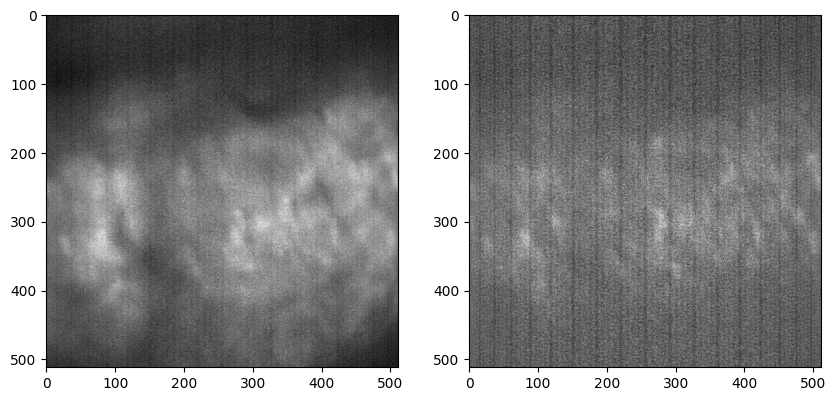

In [5]:
#deinterleave 
stack1 = tiff_stack[:, :, ::2]
stack2 = tiff_stack[:, :, 1::2]

#normalize each frame by max and min and then average them all
new_stack1 = np.zeros_like(stack1)
for i in range(stack1.shape[2]):
    new_stack1[:, :, i] = (stack1[:, :, i] - np.min(stack1[:, :, i])) / (np.max(stack1[:, :, i]) - np.min(stack1[:, :, i]))
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(np.nanmean(new_stack1, axis=2), cmap='gray')
new_stack2 = np.zeros_like(stack2)
for i in range(stack2.shape[2]):
    new_stack2[:, :, i] = (stack2[:, :, i] - np.min(stack2[:, :, i])) / (np.max(stack2[:, :, i]) - np.min(stack2[:, :, i]))
plt.subplot(1, 2, 2)
plt.imshow(np.nanmean(new_stack2, axis=2), cmap='gray')

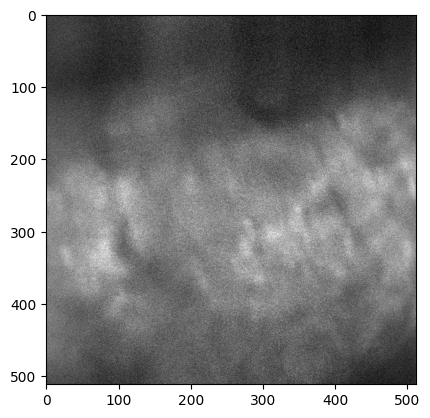

In [6]:
#subtract the forward and reverse averages from even and odd lines respectively to get a detrended stack
detrended_stack1 = np.zeros_like(stack1)
frame_forward = np.zeros([stack1.shape[0], stack1.shape[2]])
frame_reverse = np.zeros([stack1.shape[0], stack1.shape[2]])
for i in range(stack1.shape[2]):
    forward_lines = stack1[::2, :, i]
    reverse_lines = stack1[1::2, :, i]
    avg_forward = np.nanmean(forward_lines, axis=0)
    avg_reverse = np.nanmean(reverse_lines, axis=0)
    frame_forward[:, i] = avg_forward
    frame_reverse[:, i] = avg_reverse
    for j in range(stack1.shape[0]):
        if j % 2 == 0:
            detrended_stack1[j, :, i] = stack1[j, :, i] - avg_forward
        else:
            detrended_stack1[j, :, i] = stack1[j, :, i] - avg_reverse

plt.imshow(np.nanmean(detrended_stack1, axis=2), cmap='gray')

In [7]:
#save this as a tiff stack
output_file = os.path.join(path, 'detrended_stack1.tiff')
with Image.fromarray(detrended_stack1[:, :, 0]) as img:
    img.save(output_file, save_all=True, append_images=[Image.fromarray(detrended_stack1[:, :, i]) for i in range(1, detrended_stack1.shape[2])])

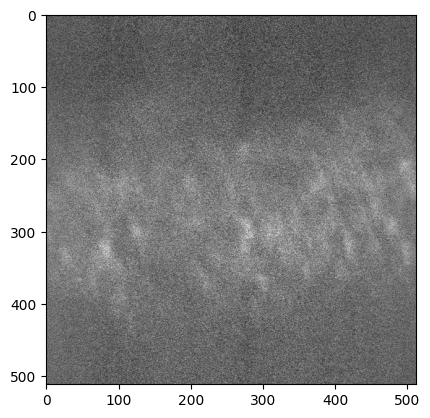

In [8]:
#subtract the forward and reverse averages from even and odd lines respectively to get a detrended stack
detrended_stack2 = np.zeros_like(stack2)
frame_forward = np.zeros([stack2.shape[0], stack2.shape[2]])
frame_reverse = np.zeros([stack2.shape[0], stack2.shape[2]])
for i in range(stack2.shape[2]):
    forward_lines = stack2[::2, :, i]
    reverse_lines = stack2[1::2, :, i]
    avg_forward = np.nanmean(forward_lines, axis=0)
    avg_reverse = np.nanmean(reverse_lines, axis=0)
    frame_forward[:, i] = avg_forward
    frame_reverse[:, i] = avg_reverse
    for j in range(stack2.shape[0]):
        if j % 2 == 0:
            detrended_stack2[j, :, i] = stack2[j, :, i] - avg_forward
        else:
            detrended_stack2[j, :, i] = stack2[j, :, i] - avg_reverse

plt.imshow(np.nanmean(detrended_stack2, axis=2), cmap='gray')

In [9]:
#save this as a tiff stack
output_file = os.path.join(path, 'detrended_stack2.tiff')
with Image.fromarray(detrended_stack2[:, :, 0]) as img:
    img.save(output_file, save_all=True, append_images=[Image.fromarray(detrended_stack2[:, :, i]) for i in range(1, detrended_stack2.shape[2])])

In [10]:
#interleave a frame from stack1 and stack2 to get a new stack with the same dimensions as the original tiff stack
interleaved_stack = np.zeros_like(tiff_stack)
interleaved_stack[:, :, ::2] = detrended_stack1
interleaved_stack[:, :, 1::2] = detrended_stack2

#save this as a tiff stack
output_file = os.path.join(path, 'detrended_interleaved_stack.tiff')
with Image.fromarray(interleaved_stack[:, :, 0]) as img:
    img.save(output_file, save_all=True, append_images=[Image.fromarray(interleaved_stack[:, :, i]) for i in range(1, interleaved_stack.shape[2])])